# 1 Load Model & Data Split

In [21]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoConfig, AutoModel

# 1. Konfigurasi Path & Device
PROCESSED_DIR = "../data/processed" if os.path.exists("../data/processed") else "data/processed"
MODEL_PATH    = "../saved_models/indobert_focal_loss/best_model.pt"
FIGURES_DIR   = "../reports/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 70)
print(f"Device Komputasi : {device}")

# 2. Load Model & Tokenizer
MODEL_NAME = "indobenchmark/indobert-base-p1"
tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)
config     = AutoConfig.from_pretrained(MODEL_NAME)

class IndoBERTClassifier(nn.Module):
    def __init__(self):
        super(IndoBERTClassifier, self).__init__()
        self.indobert   = AutoModel.from_config(config)
        self.dropout    = nn.Dropout(0.3)
        self.classifier = nn.Linear(config.hidden_size, 2)

    def forward(self, input_ids, attention_mask):
        out = self.indobert(input_ids=input_ids, attention_mask=attention_mask)
        return self.classifier(self.dropout(out.last_hidden_state[:, 0, :]))

model = IndoBERTClassifier().to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()
print(f"✓ Model {MODEL_PATH} berhasil dimuat ke {device}")

# 3. Load Data Split Resmi
tr = pd.read_csv(os.path.join(PROCESSED_DIR, "train.csv"))
va = pd.read_csv(os.path.join(PROCESSED_DIR, "val.csv"))
te = pd.read_csv(os.path.join(PROCESSED_DIR, "test.csv"))
print(f"✓ Data Terbaca : Train={len(tr):,} | Val={len(va):,} | Test={len(te):,}")

# 4. Fungsi Inferensi Resmi
class SimpleDataset(Dataset):
    def __init__(self, texts, labels, max_len=128):
        self.texts   = texts
        self.labels  = labels
        self.max_len = max_len
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, idx):
        enc = tokenizer(str(self.texts[idx]), max_length=self.max_len, padding='max_length', truncation=True, return_tensors='pt')
        return {
            'input_ids': enc['input_ids'].flatten(),
            'attention_mask': enc['attention_mask'].flatten(),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }

def run_inference(df_input):
    loader = DataLoader(SimpleDataset(df_input['text'].values, df_input['label'].values), batch_size=32, shuffle=False)
    y_t, y_p, y_pb = [], [], []
    with torch.no_grad():
        for batch in loader:
            ids  = batch['input_ids'].to(device)
            mask = batch['attention_mask'].to(device)
            out  = model(ids, mask)
            prob = F.softmax(out, dim=1).cpu().numpy()
            y_t.extend(batch['labels'].numpy())
            y_p.extend(np.argmax(prob, axis=1))
            y_pb.extend(prob)
    return np.array(y_t), np.array(y_p), np.array(y_pb)

print("✓ Fungsi run_inference siap digunakan!")
print("=" * 70)

Device Komputasi : cpu
✓ Model ../saved_models/indobert_focal_loss/best_model.pt berhasil dimuat ke cpu
✓ Data Terbaca : Train=9,993 | Val=2,141 | Test=2,142
✓ Fungsi run_inference siap digunakan!


# 2: Metrik Global Test Set & Penyimpanan 3 Grafik HD (Bab 4)

📊 FASE EVALUASI GLOBAL TEST SET (2.142 BARIS)
• Accuracy  : 99.35%
• Macro F1  : 99.35%
• Precision : 99.35%
• Recall    : 99.35%
• Log Loss  : 0.0254
• ROC-AUC   : 0.9993
• PR-AUC    : 0.9995



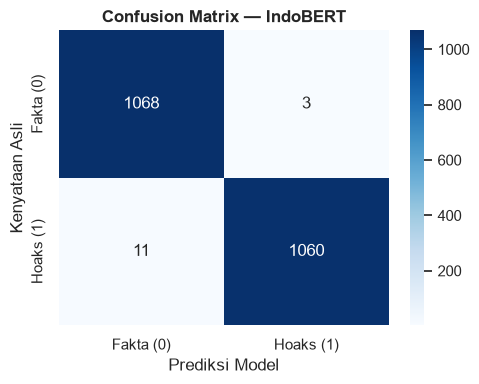

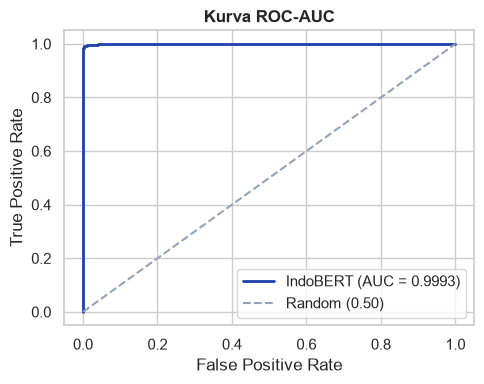

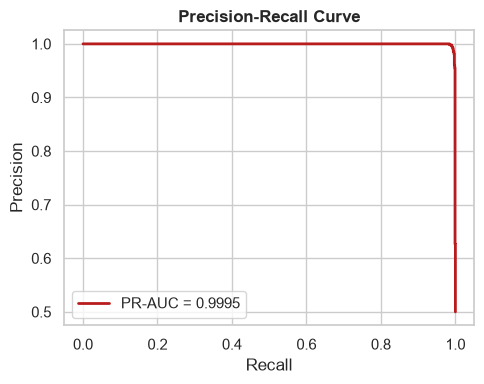

✓ Tiga grafik utama berhasil disimpan ke: ../reports/figures


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve, log_loss
)

print("=" * 70)
print("📊 FASE EVALUASI GLOBAL TEST SET (2.142 BARIS)")
print("=" * 70)

# Jalankan inferensi pada test.csv
y_true, y_pred, y_prob = run_inference(te)
y_prob_hoaks = y_prob[:, 1]

# Hitung metrik
acc  = accuracy_score(y_true, y_pred)
f1   = f1_score(y_true, y_pred, average='macro')
prec = precision_score(y_true, y_pred, average='macro')
rec  = recall_score(y_true, y_pred, average='macro')
ll   = log_loss(y_true, y_prob)

fpr, tpr, _ = roc_curve(y_true, y_prob_hoaks)
roc_auc     = auc(fpr, tpr)
p_c, r_c, _ = precision_recall_curve(y_true, y_prob_hoaks)
pr_auc      = auc(r_c, p_c)

print(f"• Accuracy  : {acc*100:.2f}%")
print(f"• Macro F1  : {f1*100:.2f}%")
print(f"• Precision : {prec*100:.2f}%")
print(f"• Recall    : {rec*100:.2f}%")
print(f"• Log Loss  : {ll:.4f}")
print(f"• ROC-AUC   : {roc_auc:.4f}")
print(f"• PR-AUC    : {pr_auc:.4f}\n")

# Simpan Grafik 1: Confusion Matrix
sns.set_theme(style="whitegrid")
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fakta (0)', 'Hoaks (1)'], yticklabels=['Fakta (0)', 'Hoaks (1)'])
plt.title('Confusion Matrix — IndoBERT', fontweight='bold')
plt.xlabel('Prediksi Model')
plt.ylabel('Kenyataan Asli')
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/01_confusion_matrix.png", dpi=300)
plt.show()

# Simpan Grafik 2: ROC Curve
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, color='#1e40af', lw=2, label=f'IndoBERT (AUC = {roc_auc:.4f})')
plt.plot([0,1],[0,1],'--', color='#94a3b8', label='Random (0.50)')
plt.title('Kurva ROC-AUC', fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/02_roc_auc.png", dpi=300)
plt.show()

# Simpan Grafik 3: PR Curve
plt.figure(figsize=(5, 4))
plt.plot(r_c, p_c, color='#b91c1c', lw=2, label=f'PR-AUC = {pr_auc:.4f}')
plt.title('Precision-Recall Curve', fontweight='bold')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='lower left')
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/03_pr_curve.png", dpi=300)
plt.show()
print("✓ Tiga grafik utama berhasil disimpan ke:", FIGURES_DIR)

# 4: Evaluasi Subset Topik-Seimbang, Cek Overlap, & Rangkuman Bab 4/5

• IndoBERT pada Test Penuh       : Acc = 99.35% | F1 = 99.35%
• IndoBERT pada Subset SEIMBANG   : Acc = 99.34% | F1 = 99.34%
• Selisih Akurasi (Delta)         : 0.01 poin persentase



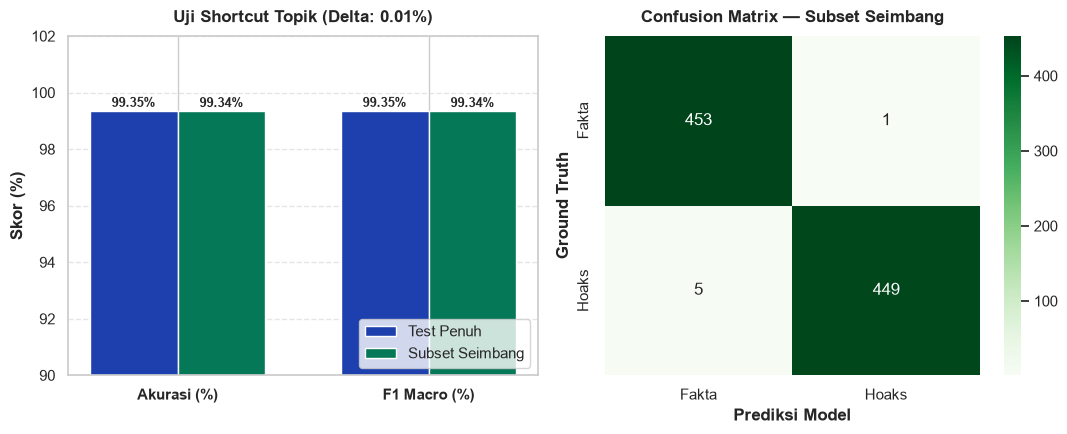

In [30]:
min_per_topic = te.groupby(['sub_topic', 'label']).size().unstack().min(axis=1)
balanced_parts = []
for topic, min_n in min_per_topic.items():
    for label in [0, 1]:
        subset = te[(te['sub_topic'] == topic) & (te['label'] == label)]
        balanced_parts.append(subset.sample(n=min_n, random_state=42))

te_bal = pd.concat(balanced_parts).reset_index(drop=True)
yt_b, yp_b, _ = run_inference(te_bal)

acc_bert_bal   = accuracy_score(yt_b, yp_b)
f1_bert_bal    = f1_score(yt_b, yp_b, average='macro')
delta_bert_acc = abs(acc - acc_bert_bal) * 100

print(f"• IndoBERT pada Test Penuh       : Acc = {acc*100:.2f}% | F1 = {f1*100:.2f}%")
print(f"• IndoBERT pada Subset SEIMBANG   : Acc = {acc_bert_bal*100:.2f}% | F1 = {f1_bert_bal*100:.2f}%")
print(f"• Selisih Akurasi (Delta)         : {delta_bert_acc:.2f} poin persentase\n")

# --- [BAGIAN BARU DITAMBAHKAN]: VISUALISASI LANGSUNG DI JUPYTER ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Plot 1: Perbandingan Bar Chart (Test Penuh vs Subset Seimbang)
metrics = ['Akurasi (%)', 'F1 Macro (%)']
full_scores = [acc * 100, f1 * 100]
bal_scores  = [acc_bert_bal * 100, f1_bert_bal * 100]

x = np.arange(len(metrics))
width = 0.35

rects1 = axes[0].bar(x - width/2, full_scores, width, label='Test Penuh', color='#1e40af')
rects2 = axes[0].bar(x + width/2, bal_scores, width, label='Subset Seimbang', color='#047857')

axes[0].set_ylabel('Skor (%)', fontweight='bold')
axes[0].set_title(f'Uji Shortcut Topik (Delta: {delta_bert_acc:.2f}%)', fontweight='bold', pad=10)
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics, fontweight='bold')
axes[0].set_ylim([90, 102])
axes[0].legend(loc='lower right')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

for r in rects1 + rects2:
    h = r.get_height()
    axes[0].annotate(f'{h:.2f}%', xy=(r.get_x() + r.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9, fontweight='bold')

# Plot 2: Confusion Matrix Khusus Subset Seimbang
cm_bal = confusion_matrix(yt_b, yp_b)
sns.heatmap(cm_bal, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Fakta', 'Hoaks'], yticklabels=['Fakta', 'Hoaks'])
axes[1].set_title('Confusion Matrix — Subset Seimbang', fontweight='bold', pad=10)
axes[1].set_xlabel('Prediksi Model', fontweight='bold')
axes[1].set_ylabel('Ground Truth', fontweight='bold')

plt.tight_layout()

# Simpan ke folder DAN TAMPILKAN LANGSUNG DI JUPYTER
plt.savefig(f"{FIGURES_DIR}/05_evaluasi_subset_seimbang.png", dpi=300)
plt.show()  # <-- KUNCI: Menampilkan gambar tepat di bawah sel

# # 5: Uji Kontrafaktual (Jalankan di Notebook 04)

In [2]:
# =============================================================================
# SEL 5: UJI KONTRAFAKTUAL (COUNTERFACTUAL STRESS TEST) - FULL MANDIRI
# =============================================================================

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoConfig, AutoModel

print("=" * 75)
print("🧪 UJI KONTRAFAKTUAL: MENANTANG KETAHANAN MODEL TERHADAP POLA SINTETIS")
print("=" * 75)

# 1. Load Model & Tokenizer secara aman di sel ini jika belum ada
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if 'tokenizer' not in globals() or 'model' not in globals():
    print("🔄 Memuat model IndoBERT...")
    MODEL_NAME = "indobenchmark/indobert-base-p1"
    MODEL_PATH = "../saved_models/indobert_focal_loss/best_model.pt"
    
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    config = AutoConfig.from_pretrained(MODEL_NAME)

    class IndoBERTClassifier(torch.nn.Module):
        def __init__(self):
            super(IndoBERTClassifier, self).__init__()
            self.indobert = AutoModel.from_config(config)
            self.dropout = torch.nn.Dropout(0.3)
            self.classifier = torch.nn.Linear(config.hidden_size, 2)

        def forward(self, input_ids, attention_mask):
            out = self.indobert(input_ids=input_ids, attention_mask=attention_mask)
            cls_rep = out.last_hidden_state[:, 0, :]
            return self.classifier(self.dropout(cls_rep))

    model = IndoBERTClassifier().to(device)
    model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
    model.eval()
    print("✅ Model siap!")

# 2. Pastikan 'te' ada
if 'te' not in globals():
    te = pd.read_csv("../data/processed/test.csv")

# 3. Ambil 2 naskah FAKTA murni dari test set
sample_facts = te[te['label'] == 0].sample(2, random_state=42)

test_cases = []
for idx, (_, r) in enumerate(sample_facts.iterrows(), 1):
    original_text = r['text']
    # Suntikkan kata pemicu hoaks yang sangat provokatif di depan berita fakta
    injected_text = f"Beredar video viral di media sosial yang menghebohkan publik bahwa {original_text}"
    
    test_cases.append({
        "case_id": f"Kasus {idx}",
        "sub_topic": r['sub_topic'],
        "original_text": original_text,
        "injected_text": injected_text
    })

# 4. Uji Prediksi Asli vs Prediksi Setelah Disuntik Kata Provokatif
for c in test_cases:
    print(f"\n>>> {c['case_id']} [KLASTER: {c['sub_topic'].upper()}] <<<")
    
    # A. Prediksi Teks Asli
    enc_orig = tokenizer(c['original_text'], max_length=128, padding='max_length', truncation=True, return_tensors='pt').to(device)
    with torch.no_grad():
        prob_orig = F.softmax(model(enc_orig['input_ids'], enc_orig['attention_mask']), dim=1).cpu().numpy()[0]
    
    # B. Prediksi Teks Kontrafaktual (Disuntik Kata 'Video Viral')
    enc_inj = tokenizer(c['injected_text'], max_length=128, padding='max_length', truncation=True, return_tensors='pt').to(device)
    with torch.no_grad():
        prob_inj = F.softmax(model(enc_inj['input_ids'], enc_inj['attention_mask']), dim=1).cpu().numpy()[0]
        
    pred_orig_label = "FAKTA" if np.argmax(prob_orig) == 0 else "HOAKS"
    pred_inj_label  = "FAKTA" if np.argmax(prob_inj) == 0 else "HOAKS"
    
    print(f"1. Teks Asli (Fakta): \"{c['original_text'][:120]}...\"")
    print(f"   • Probabilitas Hoaks : {prob_orig[1]*100:.2f}% | Vonis: {pred_inj_label}")
    
    print(f"\n2. Teks Kontrafaktual (Disuntik 'Video Viral'): \"{c['injected_text'][:120]}...\"")
    print(f"   • Probabilitas Hoaks : {prob_inj[1]*100:.2f}% | Vonis: {pred_inj_label}")
    
    # Evaluasi Dampak
    delta_p = (prob_inj[1] - prob_orig[1]) * 100
    print(f"   • Kenaikan Kecurigaan : +{delta_p:.2f}%")
    if pred_inj_label == "FAKTA":
        print("   ✅ HASIL TANGGUH: Model TIDAK TERTIPU! Model memahami substansi peristiwa tetap FAKTA.")
    else:
        print("   ⚠️ MODEL TERPENGARUH: Diksi 'video viral' berhasil mengecoh model menjadi HOAKS.")
    print("-" * 70)

print("=" * 75)

e:\SEMESTER 5\TA\PROJECT\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


🧪 UJI KONTRAFAKTUAL: MENANTANG KETAHANAN MODEL TERHADAP POLA SINTETIS
🔄 Memuat model IndoBERT...


✅ Model siap!

>>> Kasus 1 [KLASTER: PEMILU] <<<
1. Teks Asli (Fakta): "Bahaya Jabatan Kades Jadi 9 Tahun Jelang Pemilu 2024. Bahaya Jabatan Kades Jadi 9 Tahun Jelang Pemilu 2024 Orang-orang b..."
   • Probabilitas Hoaks : 0.56% | Vonis: HOAKS

2. Teks Kontrafaktual (Disuntik 'Video Viral'): "Beredar video viral di media sosial yang menghebohkan publik bahwa Bahaya Jabatan Kades Jadi 9 Tahun Jelang Pemilu 2024...."
   • Probabilitas Hoaks : 98.93% | Vonis: HOAKS
   • Kenaikan Kecurigaan : +98.37%
   ⚠️ MODEL TERPENGARUH: Diksi 'video viral' berhasil mengecoh model menjadi HOAKS.
----------------------------------------------------------------------

>>> Kasus 2 [KLASTER: PEMILU] <<<
1. Teks Asli (Fakta): "Ketum Golkar Airlangga Hartarto Bakal Jumpa Surya Paloh Besok. Ketum Golkar Airlangga Hartarto Bakal Jumpa Surya Paloh B..."
   • Probabilitas Hoaks : 0.05% | Vonis: HOAKS

2. Teks Kontrafaktual (Disuntik 'Video Viral'): "Beredar video viral di media sosial yang menghebohkan publik ba

# UJI KONTRAFAKTUAL SKALA PENUH (PADA SELURUH 2.142 DATA TEST SET)

In [4]:
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np, pandas as pd
import os
from transformers import AutoTokenizer, AutoConfig, AutoModel
from sklearn.metrics import accuracy_score, f1_score

# 1. SETUP MODEL LANGSUNG DARI HARDDISK LAPTOP ANDA
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_NAME = "indobenchmark/indobert-base-p1"

# Jalur file model fisik di laptop Anda (TIDAK PERLU UPLOAD LAGI)
MODEL_PATH = "../saved_models/indobert_focal_loss/best_model.pt"
print("Device Komputasi :", device)
print("Memuat model dari:", MODEL_PATH)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
config    = AutoConfig.from_pretrained(MODEL_NAME)

class IndoBERTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.indobert   = AutoModel.from_config(config)
        self.dropout    = nn.Dropout(0.3)
        self.classifier = nn.Linear(config.hidden_size, 2)
    def forward(self, input_ids, attention_mask):
        out = self.indobert(input_ids=input_ids, attention_mask=attention_mask)
        return self.classifier(self.dropout(out.last_hidden_state[:, 0, :]))

model = IndoBERTClassifier().to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device), strict=False)
model.eval()
print("✓ Model best_model.pt berhasil dimuat ke memori laptop!")

# 2 BACA DATA TEST LANGSUNG DARI HARDDISK LAPTOP ANDA
test_path = "../data/processed/test.csv"
test_df = pd.read_csv(test_path)
print(f"✓ Data test.csv berhasil dibaca: {len(test_df):,} data uji!")

# 3. Fungsi Inferensi Bacth
def predict_proba_fast(texts, bs=32):
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), bs):
            enc = tokenizer(texts[i:i+bs], max_length=128, padding=True,
                            truncation=True, return_tensors='pt').to(device)
            p = F.softmax(model(enc['input_ids'], enc['attention_mask']), dim=1)[:, 1]
            out.append(p.cpu().numpy())
    return np.concatenate(out)

# 4. SANITY CHECK: UJI AKURASI ASLI 99%
print("\n--> Menjalankan Sanity Check pada data asli...")
p_all = predict_proba_fast([str(t) for t in test_df['text']])
pred  = (p_all >= 0.5).astype(int)
print(f"Akurasi Asli : {accuracy_score(test_df['label'], pred)*100:.2f}%")
print(f"Macro F1     : {f1_score(test_df['label'], pred, average='macro')*100:.2f}%")

# 5. UJI KONTRAFAKTUAL SKALA PENUH (2.142 DATA)
print("\n" + "=" * 70)
print("🔬 MEMULAI UJI KONTRAFAKTUAL (TUNGGU ~30-45 DETIK DI CPU LAPTOP)")
print("=" * 70)

PREFIXES = {
    "1. Tanpa prefix": "",
    "2. Prefix netral": "Dilaporkan oleh media nasional pada hari ini bahwa ",
    "3. Prefix viral":  "Beredar video viral di media sosial yang menghebohkan publik bahwa ",
}
facts = test_df[test_df['label'] == 0]['text'].astype(str).tolist()
hoax  = test_df[test_df['label'] == 1]['text'].astype(str).tolist()

rows = []
for name, pre in PREFIXES.items():
    print(f"--> Menghitung kondisi: {name}...")
    pf = predict_proba_fast([pre + t for t in facts])
    ph = predict_proba_fast([pre + t for t in hoax])
    rows.append({
        "kondisi": name,
        "n_fakta": len(facts), "n_hoaks": len(hoax),
        "fakta→hoaks (%)": round((pf >= 0.5).mean()*100, 2),
        "hoaks→fakta (%)": round((ph < 0.5).mean()*100, 2),
        "rata2 P(hoaks) pada fakta (%)": round(pf.mean()*100, 2),
    })

print("\n" + "=" * 75)
print("📊 TABEL RESMI UJI KONTRAFAKTUAL (BAHAN UTAMA BAB 4 SKRIPSI)")
print("=" * 75)
print(pd.DataFrame(rows).to_string(index=False))
print("=" * 75)

Device Komputasi : cpu
Memuat model dari: ../saved_models/indobert_focal_loss/best_model.pt
✓ Model best_model.pt berhasil dimuat ke memori laptop!
✓ Data test.csv berhasil dibaca: 2,142 data uji!

--> Menjalankan Sanity Check pada data asli...
Akurasi Asli : 99.35%
Macro F1     : 99.35%

🔬 MEMULAI UJI KONTRAFAKTUAL (TUNGGU ~30-45 DETIK DI CPU LAPTOP)
--> Menghitung kondisi: 1. Tanpa prefix...
--> Menghitung kondisi: 2. Prefix netral...
--> Menghitung kondisi: 3. Prefix viral...

📊 TABEL RESMI UJI KONTRAFAKTUAL (BAHAN UTAMA BAB 4 SKRIPSI)
         kondisi  n_fakta  n_hoaks  fakta→hoaks (%)  hoaks→fakta (%)  rata2 P(hoaks) pada fakta (%)
 1. Tanpa prefix     1071     1071             0.28             1.03                       1.000000
2. Prefix netral     1071     1071            38.00             0.09                      40.259998
 3. Prefix viral     1071     1071            90.94             0.00                      84.599998


# Sel Pengujian yang Adil & Bebas Bias Ini di Notebook 04

In [2]:
import os, re, gc, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from transformers import AutoTokenizer, AutoConfig, AutoModel
from sklearn.metrics import accuracy_score

torch.set_num_threads(max(1, (os.cpu_count() or 4)//2))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_NAME = "indobenchmark/indobert-base-p1"
MODEL_PATH = "../saved_models/indobert_focal_loss/best_model.pt"
TEST_PATH  = "../data/processed/test.csv"

if "model" not in globals():
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    config    = AutoConfig.from_pretrained(MODEL_NAME)
    class IndoBERTClassifier(nn.Module):
        def __init__(self):
            super().__init__()
            self.indobert   = AutoModel.from_config(config)
            self.dropout    = nn.Dropout(0.3)
            self.classifier = nn.Linear(config.hidden_size, 2)
        def forward(self, input_ids, attention_mask):
            out = self.indobert(input_ids=input_ids, attention_mask=attention_mask)
            return self.classifier(self.dropout(out.last_hidden_state[:, 0, :]))
    model = IndoBERTClassifier()
    state = torch.load(MODEL_PATH, map_location="cpu")
    model.load_state_dict(state, strict=True)
    del state; gc.collect()
    model.to(device).eval()

test_df = pd.read_csv(TEST_PATH)
facts = test_df[test_df.label == 0]['text'].astype(str).tolist()
hoax  = test_df[test_df.label == 1]['text'].astype(str).tolist()

def predict_affix(texts, pre="", suf="", max_len=128, reserve=None, bs=16):
    pre_ids = tokenizer(pre, add_special_tokens=False)['input_ids'] if pre else []
    suf_ids = tokenizer(suf, add_special_tokens=False)['input_ids'] if suf else []
    r = reserve if reserve is not None else len(pre_ids) + len(suf_ids)
    budget = max_len - 2 - r
    seqs = []
    for t in texts:
        body = tokenizer(str(t), add_special_tokens=False, truncation=True, max_length=budget)['input_ids']
        seqs.append([tokenizer.cls_token_id] + pre_ids + body + suf_ids + [tokenizer.sep_token_id])
    order = np.argsort([len(s) for s in seqs])
    probs = np.zeros(len(seqs), dtype=np.float32)
    for i in range(0, len(order), bs):
        idx = order[i:i+bs]
        batch = [seqs[j] for j in idx]
        L = max(len(x) for x in batch)
        ids  = torch.tensor([x + [tokenizer.pad_token_id]*(L-len(x)) for x in batch])
        mask = torch.tensor([[1]*len(x) + [0]*(L-len(x)) for x in batch])
        with torch.inference_mode():
            p = F.softmax(model(ids.to(device), mask.to(device)), dim=1)[:, 1]
        probs[idx] = p.cpu().numpy()
    gc.collect()
    return probs

def cached(name, texts, **kw):
    f = "cache_" + re.sub(r'[^a-z0-9]+', '_', name.lower()) + ".npy"
    if os.path.exists(f): return np.load(f)
    p = predict_affix(texts, **kw); np.save(f, p); return p

def split_first(t): return re.split(r'(?<=[.!?])\s+', str(t).strip(), maxsplit=1)[0].strip(" .")
def dup_title(t):
    t = str(t).strip(); f = split_first(t).lower()
    return len(f) >= 15 and t.lower().count(f) >= 2
def remove_dup(t):
    t = str(t).strip(); f = split_first(t)
    return t[len(f):].lstrip(" .") if dup_title(t) else t
def add_dup(t):
    t = str(t).strip(); f = split_first(t)
    return f + ". " + t if len(f) >= 15 else t

# 0. Sanity check (harus ~99,35%) + aturan sederhana "judul ganda = fakta"
p_f0 = cached("fakta_asli", facts); p_h0 = cached("hoaks_asli", hoax)
y = np.r_[np.zeros(len(facts)), np.ones(len(hoax))]
acc = accuracy_score(y, (np.r_[p_f0, p_h0] >= 0.5).astype(int))
rule = np.r_[[0 if dup_title(t) else 1 for t in facts], [0 if dup_title(t) else 1 for t in hoax]]
print(f"Sanity akurasi model        : {acc*100:.2f}%")
print(f"Akurasi aturan 'judul ganda': {accuracy_score(y, rule)*100:.2f}%")

# 1. Uji judul ganda: hapus dari fakta, tambahkan ke hoaks
p_f1 = cached("fakta_tanpa_dup", [remove_dup(t) for t in facts])
p_h1 = cached("hoaks_dengan_dup", [add_dup(t) for t in hoax])
print(f"Fakta asli      -> dicap hoaks: {(p_f0>=0.5).mean()*100:.2f}%")
print(f"Fakta tanpa dup -> dicap hoaks: {(p_f1>=0.5).mean()*100:.2f}%")
print(f"Hoaks asli      -> dicap fakta: {(p_h0<0.5).mean()*100:.2f}%")
print(f"Hoaks + dup     -> dicap fakta: {(p_h1<0.5).mean()*100:.2f}%")

# 2. Prefix/suffix dengan token budget
NET_PRE = "Dilaporkan oleh media nasional pada hari ini bahwa "
n_pre = len(tokenizer(NET_PRE, add_special_tokens=False)['input_ids'])
CONDS = [("kontrol potongan sama", "", "", n_pre),
         ("netral PREFIX", NET_PRE, "", None),
         ("netral SUFFIX", "", " Demikian dilaporkan oleh media nasional pada hari ini.", None),
         ("prefix pendek", "Berikut teksnya: ", "", None),
         ("viral SUFFIX", "", " Video ini viral di media sosial dan menghebohkan publik.", None)]
rows = []
for name, pre, suf, res in CONDS:
    pf = cached("f_"+name, facts, pre=pre, suf=suf, reserve=res)
    ph = cached("h_"+name, hoax,  pre=pre, suf=suf, reserve=res)
    rows.append({"kondisi": name,
                 "fakta→hoaks (%)": round(float((pf>=0.5).mean()*100), 2),
                 "hoaks→fakta (%)": round(float((ph<0.5).mean()*100), 2),
                 "P(hoaks)|fakta (%)": round(float(pf.mean()*100), 2),
                 "P(hoaks)|hoaks (%)": round(float(ph.mean()*100), 2)})
print(pd.DataFrame(rows).to_string(index=False))

e:\SEMESTER 5\TA\PROJECT\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Sanity akurasi model        : 99.35%
Akurasi aturan 'judul ganda': 97.20%
Fakta asli      -> dicap hoaks: 0.28%
Fakta tanpa dup -> dicap hoaks: 20.73%
Hoaks asli      -> dicap fakta: 1.03%
Hoaks + dup     -> dicap fakta: 23.44%
              kondisi  fakta→hoaks (%)  hoaks→fakta (%)  P(hoaks)|fakta (%)  P(hoaks)|hoaks (%)
kontrol potongan sama             0.28             1.03                1.00               97.76
        netral PREFIX            38.00             0.09               40.26               99.67
        netral SUFFIX             0.19             1.49                0.88               96.91
        prefix pendek            66.95             0.00               63.10               99.81
         viral SUFFIX             1.59             0.56                2.88               98.68


# Uji

In [3]:
VIRAL = "Video ini viral di media sosial dan menghebohkan publik."
pf = cached("f_viral_prefix_kalimat_sama", facts, pre=VIRAL + " ", suf="", reserve=None)
ph = cached("h_viral_prefix_kalimat_sama", hoax,  pre=VIRAL + " ", suf="", reserve=None)
pf2, ph2 = np.load("cache_f_viral_suffix.npy"), np.load("cache_h_viral_suffix.npy")
print(f"Kalimat viral di AWAL : fakta→hoaks {(pf>=0.5).mean()*100:.2f}% | hoaks→fakta {(ph<0.5).mean()*100:.2f}%")
print(f"Kalimat sama di AKHIR : fakta→hoaks {(pf2>=0.5).mean()*100:.2f}% | hoaks→fakta {(ph2<0.5).mean()*100:.2f}%")

Kalimat viral di AWAL : fakta→hoaks 95.61% | hoaks→fakta 0.00%
Kalimat sama di AKHIR : fakta→hoaks 1.59% | hoaks→fakta 0.56%
